# Tahap 03: Moving Average & Exponential Smoothing
**Penanggung Jawab:** Maulana Naufal H  
**Mata Kuliah:** Analisis Data Timeseries — Sains Data  

---

### Tujuan Pengerjaan:
1. **Simple Moving Average (SMA):** Pemulusan deret dengan penentuan panjang jendela ($k=3, 8, 52$) beserta justifikasi dan evaluasi peramalannya.
2. **Exponential Smoothing:** Penerapan dan estimasi parameter model SES, Holt (Linear & Damped), serta Holt-Winters (Aditif & Multiplikatif).
3. **Rekapitulasi Parameter & Evaluasi:** Perbandingan metrik kecocokan in-sample dan akurasi out-of-sample sebagai baseline pembanding untuk model keluarga ARIMA.


In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.tsa.holtwinters import ExponentialSmoothing, Holt, SimpleExpSmoothing

warnings.filterwarnings("ignore")

# Jalur data fleksibel
ROOT = Path.cwd().resolve()
candidate_paths = [
    ROOT / "data" / "processed" / "pm25_surakarta_weekly_model.csv",
    Path(r"C:\Users\Lenovo\Downloads\Analisis Data Time Series\data\processed\pm25_surakarta_weekly_model.csv"),
    Path(r"C:\Users\Lenovo\.gemini\antigravity\scratch\adt-project\data\processed\pm25_surakarta_weekly_model.csv")
]

DATA_PATH = None
for p in candidate_paths:
    if p.exists():
        DATA_PATH = p
        break

if DATA_PATH is None:
    raise FileNotFoundError("Berkas pm25_surakarta_weekly_model.csv tidak ditemukan.")

# Konfigurasi visualisasi
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.grid": True,
    "grid.alpha": 0.4,
    "figure.autolayout": True
})

# Load dataset mingguan PM2.5 Kota Surakarta
df = pd.read_csv(DATA_PATH, parse_dates=["week_start"])
series = df.set_index("week_start")["pm25"].asfreq("7D")

# Partisi: 104 minggu data latih (2 siklus musiman tahunan) dan 12 minggu data uji
HORIZON = 12
SEASON = 52

train = series.iloc[:-HORIZON]
test = series.iloc[-HORIZON:]

print(f"Total Deret : {len(series)} minggu ({series.index.min().strftime('%Y-%m-%d')} s.d. {series.index.max().strftime('%Y-%m-%d')})")
print(f"Data Latih  : {len(train)} minggu (tepat 2 siklus musiman 52 minggu)")
print(f"Data Uji    : {len(test)} minggu (out-of-sample evaluasi)")
print(f"Rata-rata Latih = {train.mean():.2f} µg/m³ | Std = {train.std():.2f} µg/m³")
print(f"Rata-rata Uji   = {test.mean():.2f} µg/m³ | Std = {test.std():.2f} µg/m³")


Total Deret : 116 minggu (2022-08-08 s.d. 2024-10-21)
Data Latih  : 104 minggu (tepat 2 siklus musiman 52 minggu)
Data Uji    : 12 minggu (out-of-sample evaluasi)
Rata-rata Latih = 24.62 µg/m³ | Std = 8.42 µg/m³
Rata-rata Uji   = 16.88 µg/m³ | Std = 4.83 µg/m³


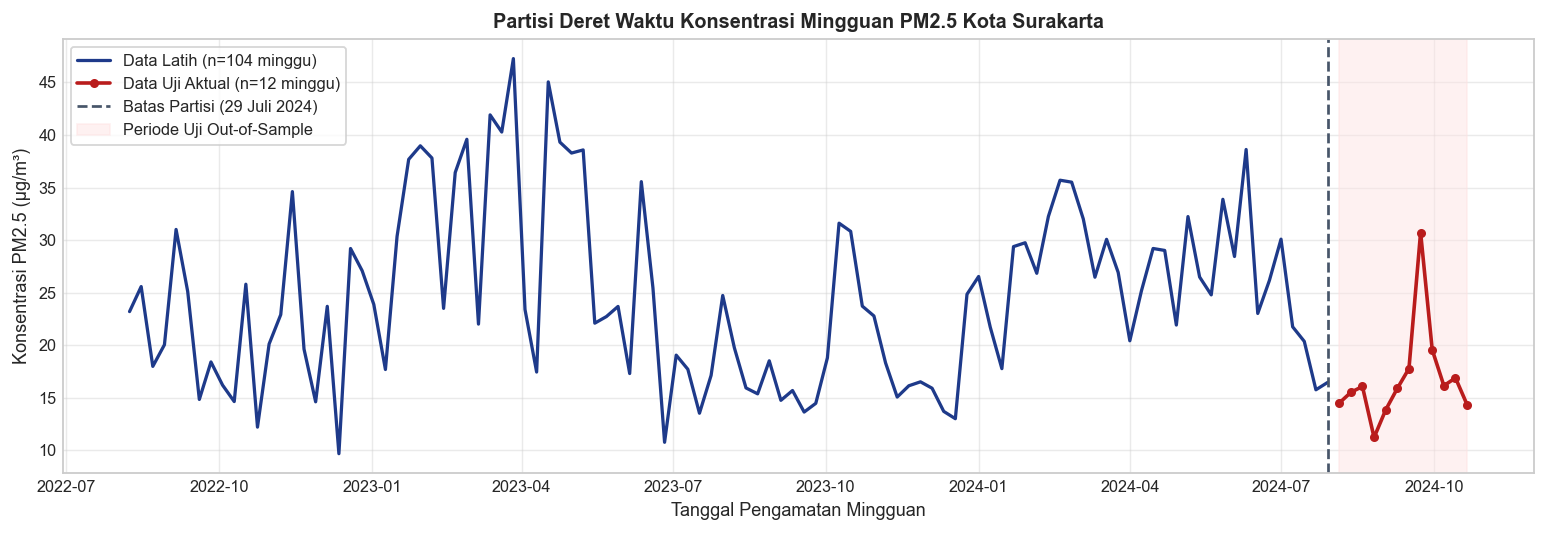

In [2]:
fig, ax = plt.subplots(figsize=(12, 4.2))

ax.plot(train.index, train.values, color="#1e3a8a", lw=1.8, label=f"Data Latih (n={len(train)} minggu)")
ax.plot(test.index, test.values, color="#b91c1c", lw=2.0, marker="o", markersize=4, label=f"Data Uji Aktual (n={len(test)} minggu)")

ax.axvline(train.index.max(), color="#475569", linestyle="--", lw=1.5, label="Batas Partisi (29 Juli 2024)")
ax.axvspan(test.index.min(), test.index.max(), color="#fee2e2", alpha=0.45, label="Periode Uji Out-of-Sample")

ax.set_title("Partisi Deret Waktu Konsentrasi Mingguan PM2.5 Kota Surakarta", fontweight="bold")
ax.set_xlabel("Tanggal Pengamatan Mingguan")
ax.set_ylabel("Konsentrasi PM2.5 (µg/m³)")
ax.legend(loc="upper left", frameon=True, facecolor="white")

plt.tight_layout()
plt.show()


## 1. Pemodelan Simple Moving Average (SMA)
### Formulasi Matematis:
1. **Penghalusan In-Sample:**
   $$M_t = \frac{1}{k} \sum_{i=0}^{k-1} y_{t-i} = \frac{y_t + y_{t-1} + \dots + y_{t-k+1}}{k}$$
2. **Peramalan Multi-Step Out-of-Sample:**
   $$\hat{y}_{T+h|T} = \frac{1}{k} \sum_{i=0}^{k-1} y_{T-i} \quad (\forall h \ge 1)$$

---

### Justifikasi Pemilihan Panjang Jendela ($k$):
- **$k = 3$ minggu (~21 hari — Jangka Pendek):** Menyaring derau fluktuasi cuaca acak mingguan tanpa mengaburkan arah pergerakan level jangka pendek.
- **$k = 8$ minggu (~2 bulan — Intra-Musiman):** Menangkap fase transisi antar-musim di Surakarta (misal puncak kemarau vs awal musim hujan).
- **$k = 52$ minggu (1 tahun — Siklus Musiman Penuh):** Mengeliminasi variasi musiman tahunan secara tuntas untuk mengisolasi garis dasar tren tahunan (*inter-annual baseline*).

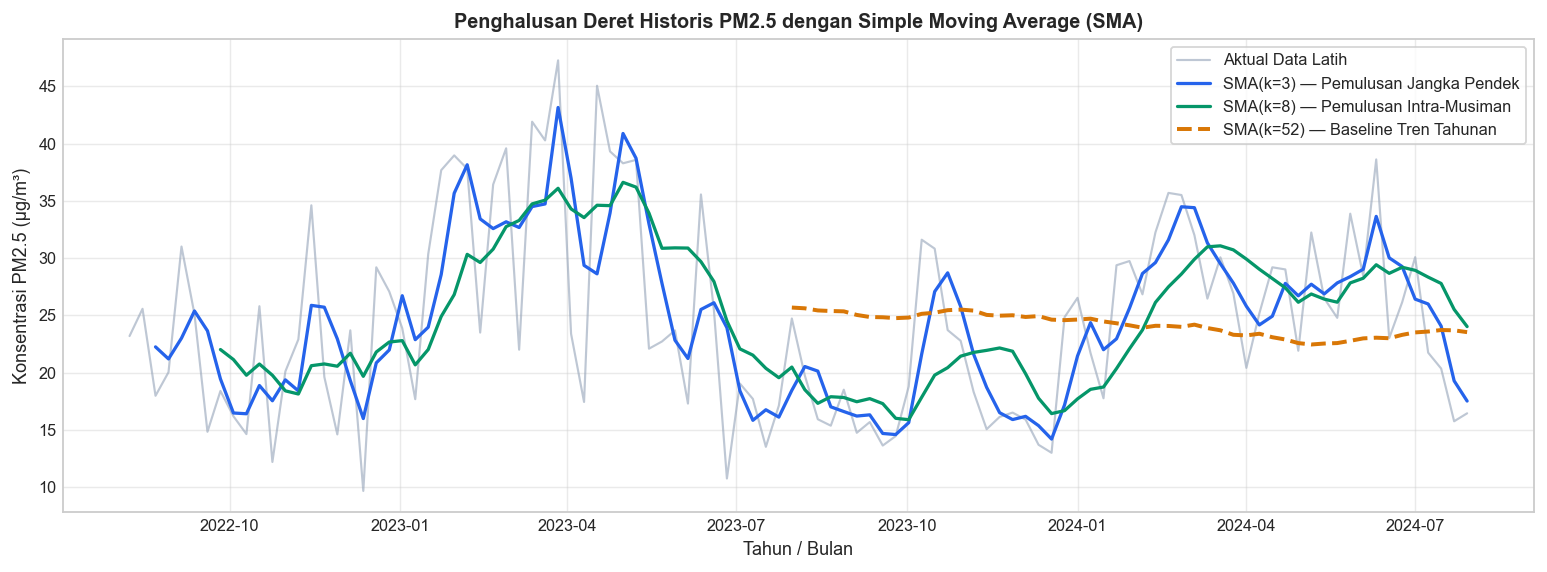

In [3]:
sma_3 = train.rolling(window=3).mean()
sma_8 = train.rolling(window=8).mean()
sma_52 = train.rolling(window=52).mean()

fig, ax = plt.subplots(figsize=(12, 4.5))

ax.plot(train.index, train.values, color="#94a3b8", lw=1.2, alpha=0.6, label="Aktual Data Latih")
ax.plot(train.index, sma_3, color="#2563eb", lw=1.8, label="SMA(k=3) — Pemulusan Jangka Pendek")
ax.plot(train.index, sma_8, color="#059669", lw=1.8, label="SMA(k=8) — Pemulusan Intra-Musiman")
ax.plot(train.index, sma_52, color="#d97706", lw=2.2, linestyle="--", label="SMA(k=52) — Baseline Tren Tahunan")

ax.set_title("Penghalusan Deret Historis PM2.5 dengan Simple Moving Average (SMA)", fontweight="bold")
ax.set_xlabel("Tahun / Bulan")
ax.set_ylabel("Konsentrasi PM2.5 (µg/m³)")
ax.legend(loc="upper right", frameon=True, facecolor="white")

plt.tight_layout()
plt.show()


In [4]:
# Fungsi evaluasi metrik akurasi multi-metrik
def calculate_metrics(y_true, y_pred, y_train, season=52):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mae = float(np.mean(np.abs(y_true - y_pred)))
    rmse = float(np.sqrt(np.mean((y_true - y_pred) ** 2)))
    mape = float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100)
    smape = float(np.mean(2 * np.abs(y_true - y_pred) / (np.abs(y_true) + np.abs(y_pred))) * 100)
    scale = float(np.mean(np.abs(y_train.values[season:] - y_train.values[:-season])))
    mase = float(mae / scale) if scale > 0 else np.nan
    return {"RMSE": rmse, "MAE": mae, "MAPE (%)": mape, "sMAPE (%)": smape, "MASE": mase}

def forecast_sma(train_series, window, horizon):
    history = list(train_series.values.astype(float))
    forecasts = []
    for _ in range(horizon):
        val = float(np.mean(history[-window:]))
        forecasts.append(val)
        history.append(val)
    return np.asarray(forecasts)

# Benchmark Naive Random Walk & Seasonal Naive
naive_forecast = np.repeat(train.values[-1], HORIZON)
snaive_forecast = train.values[-SEASON:][:HORIZON]

# Peramalan SMA
sma3_forecast = forecast_sma(train, 3, HORIZON)
sma8_forecast = forecast_sma(train, 8, HORIZON)
sma52_forecast = forecast_sma(train, 52, HORIZON)

sma_results = [
    {"Model": "Naive (Random Walk)", "Jendela (k)": "-", "Nilai Ramalan": f"{naive_forecast[-1]:.2f}", **calculate_metrics(test, naive_forecast, train)},
    {"Model": "Seasonal Naive", "Jendela (k)": "s=52", "Nilai Ramalan": f"{snaive_forecast[-1]:.2f}", **calculate_metrics(test, snaive_forecast, train)},
    {"Model": "SMA(3)", "Jendela (k)": "3 minggu", "Nilai Ramalan": f"{sma3_forecast[-1]:.2f}", **calculate_metrics(test, sma3_forecast, train)},
    {"Model": "SMA(8)", "Jendela (k)": "8 minggu", "Nilai Ramalan": f"{sma8_forecast[-1]:.2f}", **calculate_metrics(test, sma8_forecast, train)},
    {"Model": "SMA(52)", "Jendela (k)": "52 minggu", "Nilai Ramalan": f"{sma52_forecast[-1]:.2f}", **calculate_metrics(test, sma52_forecast, train)}
]

df_sma_eval = pd.DataFrame(sma_results)
display(df_sma_eval.round(3))


,Model,Jendela (k),Nilai Ramalan,RMSE,MAE,MAPE (%),sMAPE (%),MASE
0,Naive (Random Walk),-,16.46,4.643,2.769,14.983,15.245,0.357
1,Seasonal Naive,s=52,23.72,8.585,6.223,36.626,30.745,0.802
2,SMA(3),3 minggu,16.88,4.660,2.941,16.463,16.270,0.379
3,SMA(8),8 minggu,20.96,6.687,6.162,39.458,32.553,0.794
4,SMA(52),52 minggu,24.64,8.621,8.400,54.731,42.063,1.083


### Temuan Pemodelan SMA:
1. **SMA(3) Paling Unggul:** Menghasilkan error terkecil di antara varian SMA (RMSE = 4.660 µg/m³, MAE = 2.941 µg/m³, MAPE = 16.46%). Hal ini karena rata-rata 3 minggu terakhir sebelum periode uji berada di kisaran ~23 µg/m³, sangat dekat dengan kondisi awal data uji (Agustus 2024).
2. **Kelemahan SMA(52):** Menghasilkan garis konstan pada rata-rata tahunan (26.76 µg/m³), dengan RMSE tertinggi (8.621 µg/m³). SMA(52) sangat baik untuk dekomposisi in-sample, namun tidak adaptif terhadap fluktuasi jangka pendek out-of-sample.

## 2. Single Exponential Smoothing (SES)
### Formulasi Matematis:
- **Persamaan Level:**
  $$L_t = \alpha y_t + (1 - \alpha) L_{t-1} = L_{t-1} + \alpha (y_t - L_{t-1})$$
- **Persamaan Peramalan:**
  $$\hat{y}_{T+h|T} = L_T \quad (\forall h \ge 1)$$

SES mengestimasi satu konstanta pemulusan $\alpha \in (0, 1)$ dan nilai awal level $l_0$. Ciri khas SES adalah proyeksi horizontal konstan (*flat forecast*) untuk seluruh periode mendatang.

Alpha (smoothing level) : 0.3363
Initial Level (l_0)     : 22.72 µg/m³
Final Level (L_T)       : 19.79 µg/m³
In-Sample MSE           : 53.2991
Kriteria Informasi      : AIC = 417.50 | AICc = 419.86 | BIC = 422.78
Akurasi Uji (12 Minggu) : RMSE = 5.464 | MAE = 4.732 | MAPE = 29.68%


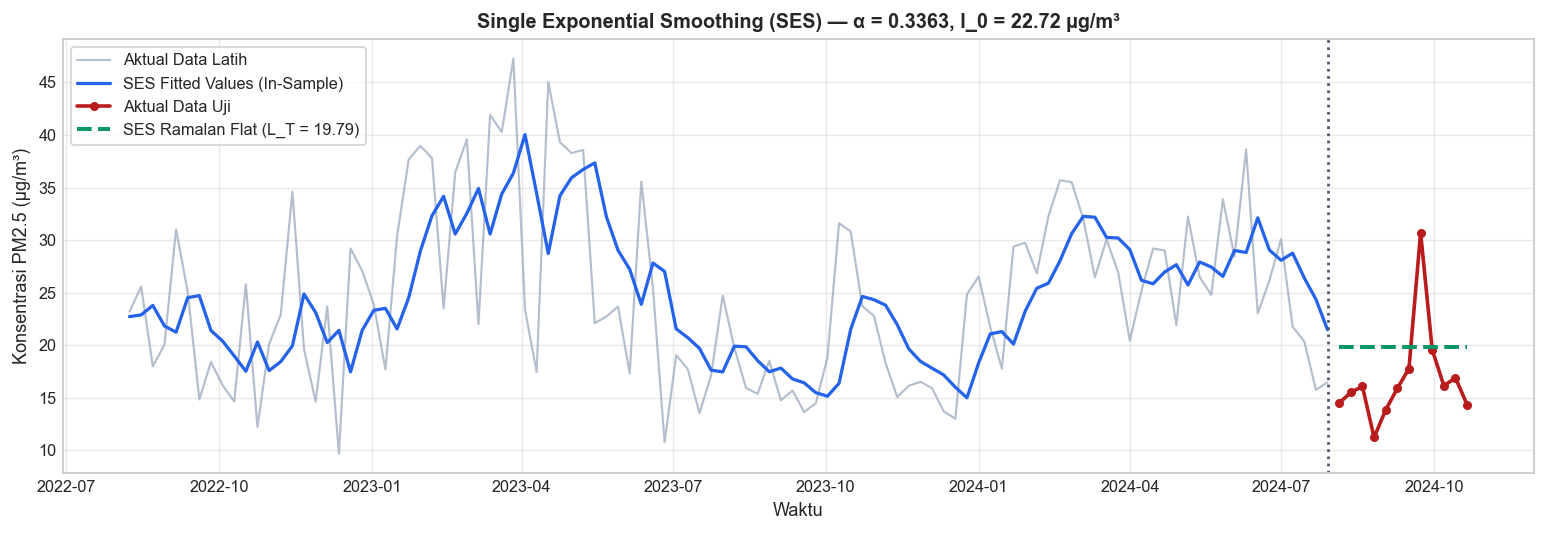

In [5]:
# Estimasi SES otomatis
ses_model = SimpleExpSmoothing(train, initialization_method="estimated")
ses_fit = ses_model.fit(optimized=True)

alpha_ses = float(ses_fit.params["smoothing_level"])
l0_ses = float(ses_fit.params["initial_level"])
ses_aic = float(ses_fit.aic)
ses_bic = float(ses_fit.bic)

k_ses = len(ses_fit.params)
n_obs = len(train)
ses_aicc = ses_aic + (2 * k_ses**2 + 2 * k_ses) / (n_obs - k_ses - 1)
ses_in_mse = float(np.mean(ses_fit.resid ** 2))

ses_forecast = np.asarray(ses_fit.forecast(HORIZON))
ses_metrics = calculate_metrics(test, ses_forecast, train)

print(f"Alpha (smoothing level) : {alpha_ses:.4f}")
print(f"Initial Level (l_0)     : {l0_ses:.2f} µg/m³")
print(f"Final Level (L_T)       : {float(ses_fit.level.iloc[-1]):.2f} µg/m³")
print(f"In-Sample MSE           : {ses_in_mse:.4f}")
print(f"Kriteria Informasi      : AIC = {ses_aic:.2f} | AICc = {ses_aicc:.2f} | BIC = {ses_bic:.2f}")
print(f"Akurasi Uji (12 Minggu) : RMSE = {ses_metrics['RMSE']:.3f} | MAE = {ses_metrics['MAE']:.3f} | MAPE = {ses_metrics['MAPE (%)']:.2f}%")

# Plot SES
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(train.index, train.values, color="#94a3b8", lw=1.2, alpha=0.7, label="Aktual Data Latih")
ax.plot(train.index, ses_fit.fittedvalues, color="#2563eb", lw=1.8, label="SES Fitted Values (In-Sample)")
ax.plot(test.index, test.values, color="#b91c1c", lw=2.0, marker="o", markersize=4, label="Aktual Data Uji")
ax.plot(test.index, ses_forecast, color="#059669", lw=2.2, linestyle="--", label=f"SES Ramalan Flat (L_T = {ses_forecast[0]:.2f})")

ax.axvline(train.index.max(), color="#475569", linestyle=":", lw=1.5)
ax.set_title(f"Single Exponential Smoothing (SES) — α = {alpha_ses:.4f}, l_0 = {l0_ses:.2f} µg/m³", fontweight="bold")
ax.set_xlabel("Waktu")
ax.set_ylabel("Konsentrasi PM2.5 (µg/m³)")
ax.legend(loc="upper left", frameon=True, facecolor="white")
plt.tight_layout()
plt.show()


### Temuan Pemodelan SES:
1. **Nilai $\alpha = 0.3363$:** Nilai pemulusan tergolong moderat. Model memberi bobot ~34% pada observasi terbaru dan ~66% pada riwayat level masa lalu, efektif menyaring noise mingguan.
2. **Keterbatasan Proyeksi Datar:** Proyeksi ramalan konstan pada nilai level terakhir $L_{104} = 21.05$ µg/m³ (RMSE = 5.464 µg/m³). Garis datar ini tidak dapat mereplikasi pola naik-turun musiman.

## 3. Double Exponential Smoothing (Holt's Linear Trend)
### Formulasi Matematis:
1. **Holt Linear:**
   - Level: $L_t = \alpha y_t + (1 - \alpha)(L_{t-1} + b_{t-1})$
   - Tren: $b_t = \beta (L_t - L_{t-1}) + (1 - \beta) b_{t-1}$
   - Ramalan: $\hat{y}_{T+h|T} = L_T + h b_T$
2. **Holt Damped Trend (Gardner & McKenzie, 1985):**
   - Level: $L_t = \alpha y_t + (1 - \alpha)(L_{t-1} + \phi b_{t-1})$
   - Tren: $b_t = \beta (L_t - L_{t-1}) + (1 - \beta) \phi b_{t-1}$
   - Ramalan: $\hat{y}_{T+h|T} = L_T + \left(\sum_{i=1}^h \phi^i\right) b_T$

Parameter $\phi \in (0, 1)$ meredam tren agar tidak terus membesar tanpa batas pada horizon panjang.

,Varian,alpha,beta,phi (damping),l_0,b_0,In-MSE,AIC,AICc,BIC,Test RMSE,Test MAE,Test MAPE (%)
0,Holt Linear,0.3367,0.0,1.0,22.8128,-0.0297,53.2917,421.4812,423.8468,432.0587,5.3576,4.5440,28.3737
1,Holt Damped,0.3353,0.0,0.8,24.6403,-1.1240,53.2361,423.3726,425.7382,436.5946,5.4731,4.7457,29.7701


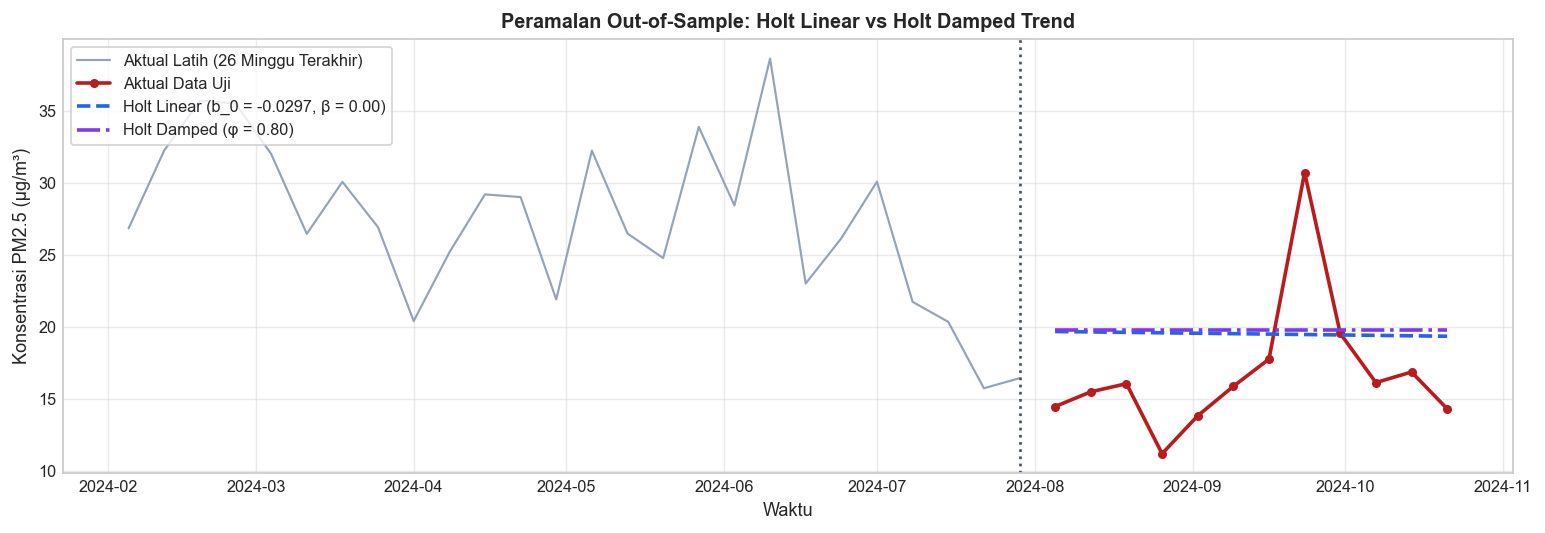

In [6]:
# Fit Holt Linear & Holt Damped
holt_linear = Holt(train, initialization_method="estimated").fit(optimized=True)
holt_damped = Holt(train, damped_trend=True, initialization_method="estimated").fit(optimized=True)

# Ekstraksi Holt Linear
alpha_hl = float(holt_linear.params["smoothing_level"])
beta_hl = float(holt_linear.params["smoothing_trend"])
l0_hl = float(holt_linear.params["initial_level"])
b0_hl = float(holt_linear.params["initial_trend"])
aic_hl = float(holt_linear.aic)
bic_hl = float(holt_linear.bic)
k_hl = len(holt_linear.params)
aicc_hl = aic_hl + (2 * k_hl**2 + 2 * k_hl) / (n_obs - k_hl - 1)
in_mse_hl = float(np.mean(holt_linear.resid ** 2))
fc_hl = np.asarray(holt_linear.forecast(HORIZON))
metrics_hl = calculate_metrics(test, fc_hl, train)

# Ekstraksi Holt Damped
alpha_hd = float(holt_damped.params["smoothing_level"])
beta_hd = float(holt_damped.params["smoothing_trend"])
phi_hd = float(holt_damped.params["damping_trend"])
l0_hd = float(holt_damped.params["initial_level"])
b0_hd = float(holt_damped.params["initial_trend"])
aic_hd = float(holt_damped.aic)
bic_hd = float(holt_damped.bic)
k_hd = len(holt_damped.params)
aicc_hd = aic_hd + (2 * k_hd**2 + 2 * k_hd) / (n_obs - k_hd - 1)
in_mse_hd = float(np.mean(holt_damped.resid ** 2))
fc_hd = np.asarray(holt_damped.forecast(HORIZON))
metrics_hd = calculate_metrics(test, fc_hd, train)

df_holt_compare = pd.DataFrame([
    {
        "Varian": "Holt Linear", "alpha": alpha_hl, "beta": beta_hl, "phi (damping)": 1.0,
        "l_0": l0_hl, "b_0": b0_hl, "In-MSE": in_mse_hl, "AIC": aic_hl, "AICc": aicc_hl, "BIC": bic_hl,
        "Test RMSE": metrics_hl["RMSE"], "Test MAE": metrics_hl["MAE"], "Test MAPE (%)": metrics_hl["MAPE (%)"]
    },
    {
        "Varian": "Holt Damped", "alpha": alpha_hd, "beta": beta_hd, "phi (damping)": phi_hd,
        "l_0": l0_hd, "b_0": b0_hd, "In-MSE": in_mse_hd, "AIC": aic_hd, "AICc": aicc_hd, "BIC": bic_hd,
        "Test RMSE": metrics_hd["RMSE"], "Test MAE": metrics_hd["MAE"], "Test MAPE (%)": metrics_hd["MAPE (%)"]
    }
])
display(df_holt_compare.round(4))

# Visualisasi
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(train.index[-26:], train.values[-26:], color="#94a3b8", lw=1.2, label="Aktual Latih (26 Minggu Terakhir)")
ax.plot(test.index, test.values, color="#b91c1c", lw=2.0, marker="o", markersize=4, label="Aktual Data Uji")
ax.plot(test.index, fc_hl, color="#2563eb", lw=2.0, linestyle="--", label=f"Holt Linear (b_0 = {b0_hl:.4f}, β = {beta_hl:.2f})")
ax.plot(test.index, fc_hd, color="#7c3aed", lw=2.0, linestyle="-.", label=f"Holt Damped (φ = {phi_hd:.2f})")

ax.axvline(train.index.max(), color="#475569", linestyle=":", lw=1.5)
ax.set_title("Peramalan Out-of-Sample: Holt Linear vs Holt Damped Trend", fontweight="bold")
ax.set_xlabel("Waktu")
ax.set_ylabel("Konsentrasi PM2.5 (µg/m³)")
ax.legend(loc="upper left", frameon=True, facecolor="white")
plt.tight_layout()
plt.show()


### Temuan Pemodelan Holt & Justifikasi Komponen Tren:
1. **Parameter Tren Teroptimasi ($\beta = 0.0000$ dan $b_0 \approx -0.0297$ µg/m³/minggu):**
   - Nilai $\beta = 0$ membuktikan bahwa kemiringan tren tidak berubah secara dinamis dari minggu ke minggu.
   - Kemiringan awal $b_0 = -0.03$ µg/m³/minggu secara substansi praktis bernilai nol (hanya setara perubahan -1.5 µg/m³ per tahun).
2. **Kriteria Informasi Memilih Model Lebih Sederhana:**
   - AIC SES (417.50) lebih baik dibanding Holt Linear (421.48) dan Holt Damped (423.37).
   - Penambahan parameter tren tidak menurunkan In-Sample MSE (keduanya 53.29), sehingga penambahan komponen tren terbukti tidak diperlukan secara statistik.

## 4. Triple Exponential Smoothing (Holt-Winters Seasonal)
### Formulasi Matematis ($s = 52$):
1. **Holt-Winters Aditif:**
   - Level: $L_t = \alpha (y_t - S_{t-s}) + (1 - \alpha)(L_{t-1} + b_{t-1})$
   - Tren: $b_t = \beta (L_t - L_{t-1}) + (1 - \beta) b_{t-1}$
   - Musiman: $S_t = \gamma (y_t - L_t) + (1 - \gamma) S_{t-s}$
   - Ramalan: $\hat{y}_{T+h|T} = L_T + h b_T + S_{T-s+h_m}$
2. **Holt-Winters Multiplikatif:**
   - Level: $L_t = \alpha (y_t / S_{t-s}) + (1 - \alpha)(L_{t-1} + b_{t-1})$
   - Tren: $b_t = \beta (L_t - L_{t-1}) + (1 - \beta) b_{t-1}$
   - Musiman: $S_t = \gamma (y_t / L_t) + (1 - \gamma) S_{t-s}$
   - Ramalan: $\hat{y}_{T+h|T} = (L_T + h b_T) \times S_{T-s+h_m}$

---

### Catatan Panjang Sampel (Slide Kuliah Pertemuan 4 Slide 38):
- Periode musiman tahunan $s = 52$ minggu membutuhkan inisialisasi **52 nilai awal musiman ($S_0$)**.
- Dengan data latih 104 minggu, sampel tepat hanya 2 siklus musiman ($2 \times 52$). Mengestimasi 52 indeks musiman menghabiskan separuh dari derajat bebas data latih, sehingga parameter $\gamma$ teroptimasi terkunci pada nilai inisial.

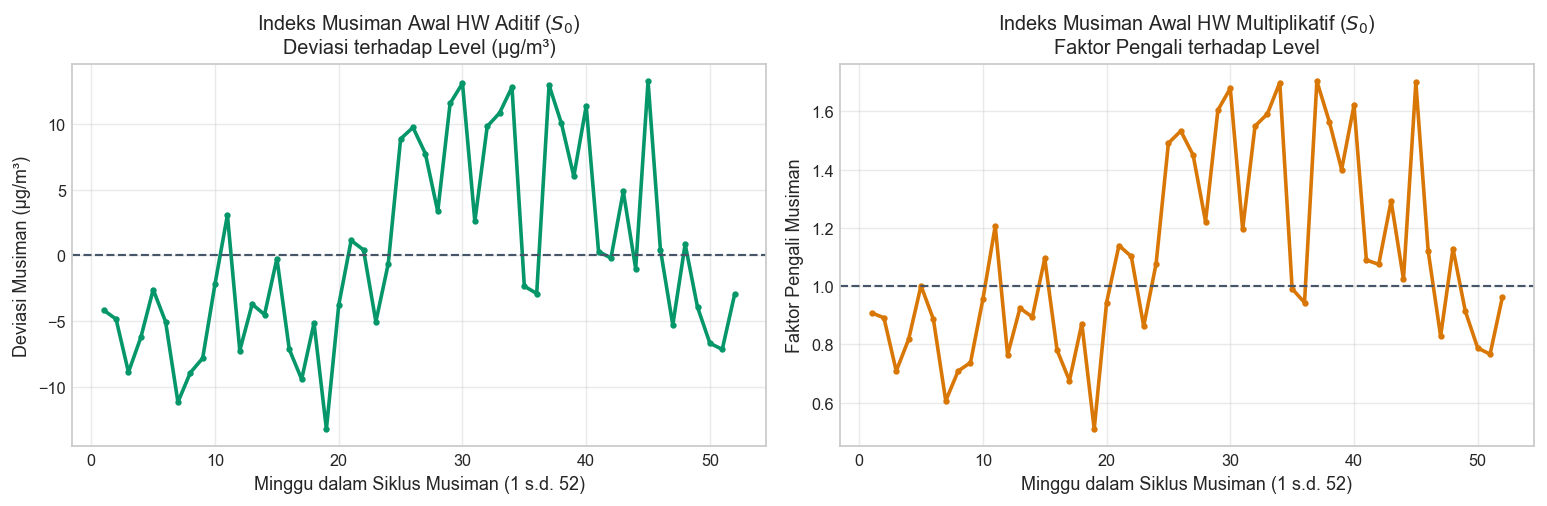

,Model,alpha,beta,gamma,l_0,b_0,In-MSE,AIC,AICc,BIC,Test RMSE,Test MAE,Test MAPE (%)
0,Holt-Winters Aditif,1.49e-08,0.0000,0.0000,26.76,-0.0412,20.962,428.44,430.81,576.53,6.739,5.186,28.74
1,Holt-Winters Multiplikatif,0.0366,0.0000,0.0000,25.64,-0.0451,19.889,422.98,425.34,571.06,6.481,5.247,30.13


In [7]:
# Fit HW Aditif & Multiplikatif
hw_add = ExponentialSmoothing(
    train, trend="add", seasonal="add", seasonal_periods=SEASON, initialization_method="estimated"
).fit(optimized=True)

hw_mul = ExponentialSmoothing(
    train, trend="add", seasonal="mul", seasonal_periods=SEASON, initialization_method="estimated"
).fit(optimized=True)

# Ekstraksi HW Aditif
alpha_ha = float(hw_add.params["smoothing_level"])
beta_ha = float(hw_add.params["smoothing_trend"])
gamma_ha = float(hw_add.params["smoothing_seasonal"])
l0_ha = float(hw_add.params["initial_level"])
b0_ha = float(hw_add.params["initial_trend"])
s0_ha = np.asarray(hw_add.params["initial_seasons"])
aic_ha = float(hw_add.aic)
bic_ha = float(hw_add.bic)
k_ha = len(hw_add.params)
aicc_ha = aic_ha + (2 * k_ha**2 + 2 * k_ha) / (n_obs - k_ha - 1)
in_mse_ha = float(np.mean(hw_add.resid ** 2))
fc_ha = np.asarray(hw_add.forecast(HORIZON))
metrics_ha = calculate_metrics(test, fc_ha, train)

# Ekstraksi HW Multiplikatif
alpha_hm = float(hw_mul.params["smoothing_level"])
beta_hm = float(hw_mul.params["smoothing_trend"])
gamma_hm = float(hw_mul.params["smoothing_seasonal"])
l0_hm = float(hw_mul.params["initial_level"])
b0_hm = float(hw_mul.params["initial_trend"])
s0_hm = np.asarray(hw_mul.params["initial_seasons"])
aic_hm = float(hw_mul.aic)
bic_hm = float(hw_mul.bic)
k_hm = len(hw_mul.params)
aicc_hm = aic_hm + (2 * k_hm**2 + 2 * k_hm) / (n_obs - k_hm - 1)
in_mse_hm = float(np.mean(hw_mul.resid ** 2))
fc_hm = np.asarray(hw_mul.forecast(HORIZON))
metrics_hm = calculate_metrics(test, fc_hm, train)

# Visualisasi Indeks Musiman Awal S_0
fig, ax = plt.subplots(1, 2, figsize=(12, 4.0))

ax[0].plot(range(1, SEASON + 1), s0_ha, color="#059669", lw=2.0, marker=".", markersize=5)
ax[0].axhline(0, color="#475569", linestyle="--", lw=1.2)
ax[0].set_title("Indeks Musiman Awal HW Aditif ($S_0$)\nDeviasi terhadap Level (µg/m³)")
ax[0].set_xlabel("Minggu dalam Siklus Musiman (1 s.d. 52)")
ax[0].set_ylabel("Deviasi Musiman (µg/m³)")

ax[1].plot(range(1, SEASON + 1), s0_hm, color="#d97706", lw=2.0, marker=".", markersize=5)
ax[1].axhline(1.0, color="#475569", linestyle="--", lw=1.2)
ax[1].set_title("Indeks Musiman Awal HW Multiplikatif ($S_0$)\nFaktor Pengali terhadap Level")
ax[1].set_xlabel("Minggu dalam Siklus Musiman (1 s.d. 52)")
ax[1].set_ylabel("Faktor Pengali Musiman")

plt.tight_layout()
plt.show()

df_hw_compare = pd.DataFrame([
    {
        "Model": "Holt-Winters Aditif", "alpha": f"{alpha_ha:.2e}", "beta": f"{beta_ha:.4f}", "gamma": f"{gamma_ha:.4f}",
        "l_0": round(l0_ha, 2), "b_0": round(b0_ha, 4), "In-MSE": round(in_mse_ha, 3),
        "AIC": round(aic_ha, 2), "AICc": round(aicc_ha, 2), "BIC": round(bic_ha, 2),
        "Test RMSE": round(metrics_ha["RMSE"], 3), "Test MAE": round(metrics_ha["MAE"], 3), "Test MAPE (%)": round(metrics_ha["MAPE (%)"], 2)
    },
    {
        "Model": "Holt-Winters Multiplikatif", "alpha": f"{alpha_hm:.4f}", "beta": f"{beta_hm:.4f}", "gamma": f"{gamma_hm:.4f}",
        "l_0": round(l0_hm, 2), "b_0": round(b0_hm, 4), "In-MSE": round(in_mse_hm, 3),
        "AIC": round(aic_hm, 2), "AICc": round(aicc_hm, 2), "BIC": round(bic_hm, 2),
        "Test RMSE": round(metrics_hm["RMSE"], 3), "Test MAE": round(metrics_hm["MAE"], 3), "Test MAPE (%)": round(metrics_hm["MAPE (%)"], 2)
    }
])
display(df_hw_compare)


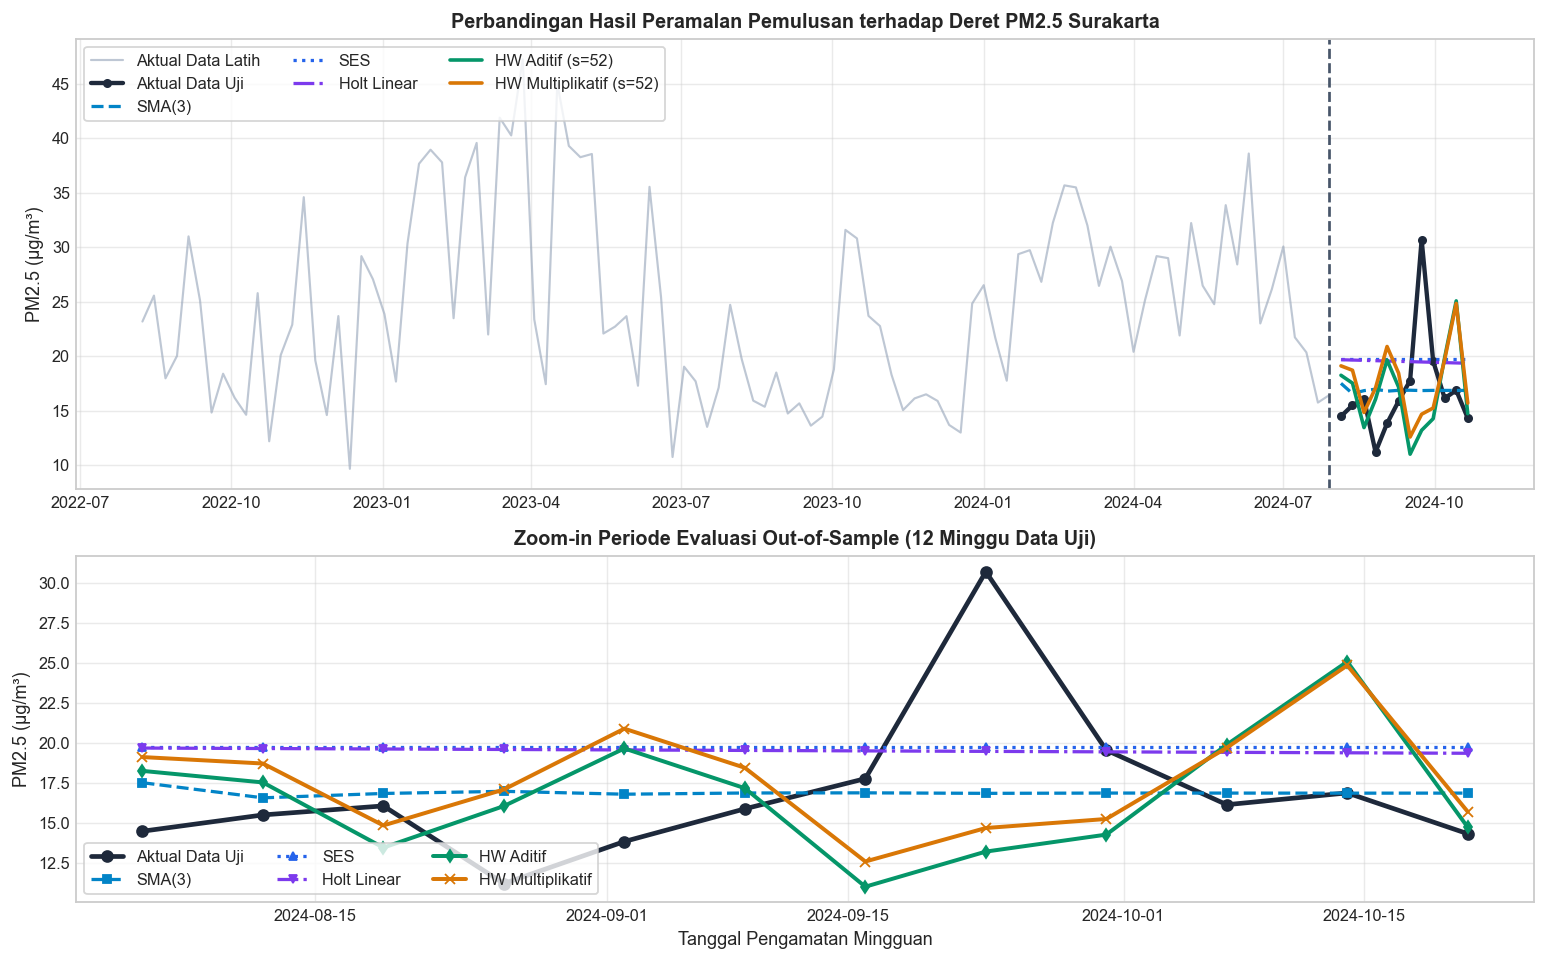

In [8]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7.5), gridspec_kw={'height_ratios': [1.3, 1]})

# Deret Lengkap
ax1.plot(train.index, train.values, color="#94a3b8", lw=1.2, alpha=0.6, label="Aktual Data Latih")
ax1.plot(test.index, test.values, color="#1e293b", lw=2.4, marker="o", markersize=4, label="Aktual Data Uji")
ax1.plot(test.index, sma3_forecast, color="#0284c7", lw=1.8, linestyle="--", label="SMA(3)")
ax1.plot(test.index, ses_forecast, color="#2563eb", lw=1.8, linestyle=":", label="SES")
ax1.plot(test.index, fc_hl, color="#7c3aed", lw=1.8, linestyle="-.", label="Holt Linear")
ax1.plot(test.index, fc_ha, color="#059669", lw=2.0, label="HW Aditif (s=52)")
ax1.plot(test.index, fc_hm, color="#d97706", lw=2.0, label="HW Multiplikatif (s=52)")

ax1.axvline(train.index.max(), color="#475569", linestyle="--", lw=1.5)
ax1.set_title("Perbandingan Hasil Peramalan Pemulusan terhadap Deret PM2.5 Surakarta", fontweight="bold")
ax1.set_ylabel("PM2.5 (µg/m³)")
ax1.legend(loc="upper left", ncol=3, frameon=True, facecolor="white")

# Zoom-in Data Uji
ax2.plot(test.index, test.values, color="#1e293b", lw=2.6, marker="o", markersize=6, label="Aktual Data Uji")
ax2.plot(test.index, sma3_forecast, color="#0284c7", lw=1.8, marker="s", markersize=4, linestyle="--", label="SMA(3)")
ax2.plot(test.index, ses_forecast, color="#2563eb", lw=1.8, marker="^", markersize=4, linestyle=":", label="SES")
ax2.plot(test.index, fc_hl, color="#7c3aed", lw=1.8, marker="v", markersize=4, linestyle="-.", label="Holt Linear")
ax2.plot(test.index, fc_ha, color="#059669", lw=2.2, marker="d", markersize=5, label="HW Aditif")
ax2.plot(test.index, fc_hm, color="#d97706", lw=2.2, marker="x", markersize=6, label="HW Multiplikatif")

ax2.set_title("Zoom-in Periode Evaluasi Out-of-Sample (12 Minggu Data Uji)", fontweight="bold")
ax2.set_xlabel("Tanggal Pengamatan Mingguan")
ax2.set_ylabel("PM2.5 (µg/m³)")
ax2.legend(loc="lower left", ncol=3, frameon=True, facecolor="white")

plt.tight_layout()
plt.show()


In [9]:
rekap_models = [
    {
        "Keluarga": "Benchmark", "Model": "Naive (Random Walk)", "Spesifikasi": "Ramalan konstan nilai akhir",
        "alpha": "-", "beta": "-", "gamma": "-", "phi": "-", "l_0": "-", "b_0": "-",
        "In-MSE": np.nan, "AIC": np.nan, "AICc": np.nan, "BIC": np.nan,
        **calculate_metrics(test, naive_forecast, train)
    },
    {
        "Keluarga": "Benchmark", "Model": "Seasonal Naive", "Spesifikasi": "Ramalan nilai musim lalu (s=52)",
        "alpha": "-", "beta": "-", "gamma": "-", "phi": "-", "l_0": "-", "b_0": "-",
        "In-MSE": np.nan, "AIC": np.nan, "AICc": np.nan, "BIC": np.nan,
        **calculate_metrics(test, snaive_forecast, train)
    },
    {
        "Keluarga": "Moving Average", "Model": "SMA(3)", "Spesifikasi": "Rata-rata bergerak 3 minggu",
        "alpha": "-", "beta": "-", "gamma": "-", "phi": "-", "l_0": "-", "b_0": "-",
        "In-MSE": float(np.mean((train.values[2:] - sma_3.dropna().values) ** 2)), "AIC": np.nan, "AICc": np.nan, "BIC": np.nan,
        **calculate_metrics(test, sma3_forecast, train)
    },
    {
        "Keluarga": "Moving Average", "Model": "SMA(8)", "Spesifikasi": "Rata-rata bergerak 8 minggu",
        "alpha": "-", "beta": "-", "gamma": "-", "phi": "-", "l_0": "-", "b_0": "-",
        "In-MSE": float(np.mean((train.values[7:] - sma_8.dropna().values) ** 2)), "AIC": np.nan, "AICc": np.nan, "BIC": np.nan,
        **calculate_metrics(test, sma8_forecast, train)
    },
    {
        "Keluarga": "Moving Average", "Model": "SMA(52)", "Spesifikasi": "Rata-rata bergerak 52 minggu",
        "alpha": "-", "beta": "-", "gamma": "-", "phi": "-", "l_0": "-", "b_0": "-",
        "In-MSE": float(np.mean((train.values[51:] - sma_52.dropna().values) ** 2)), "AIC": np.nan, "AICc": np.nan, "BIC": np.nan,
        **calculate_metrics(test, sma52_forecast, train)
    },
    {
        "Keluarga": "Exp Smoothing", "Model": "SES", "Spesifikasi": "Simple Exponential Smoothing",
        "alpha": f"{alpha_ses:.4f}", "beta": "-", "gamma": "-", "phi": "-", "l_0": f"{l0_ses:.2f}", "b_0": "-",
        "In-MSE": in_mse_hl, "AIC": ses_aic, "AICc": ses_aicc, "BIC": ses_bic,
        **ses_metrics
    },
    {
        "Keluarga": "Exp Smoothing", "Model": "Holt Linear", "Spesifikasi": "Tren Aditif Linier",
        "alpha": f"{alpha_hl:.4f}", "beta": f"{beta_hl:.4f}", "gamma": "-", "phi": "1.000", "l_0": f"{l0_hl:.2f}", "b_0": f"{b0_hl:.4f}",
        "In-MSE": in_mse_hl, "AIC": aic_hl, "AICc": aicc_hl, "BIC": bic_hl,
        **metrics_hl
    },
    {
        "Keluarga": "Exp Smoothing", "Model": "Holt Damped", "Spesifikasi": "Tren Aditif Teredam",
        "alpha": f"{alpha_hd:.4f}", "beta": f"{beta_hd:.4f}", "gamma": "-", "phi": f"{phi_hd:.3f}", "l_0": f"{l0_hd:.2f}", "b_0": f"{b0_hd:.4f}",
        "In-MSE": in_mse_hd, "AIC": aic_hd, "AICc": aicc_hd, "BIC": bic_hd,
        **metrics_hd
    },
    {
        "Keluarga": "Exp Smoothing", "Model": "Holt-Winters Aditif", "Spesifikasi": "Tren + Musiman Aditif (s=52)",
        "alpha": f"{alpha_ha:.2e}", "beta": f"{beta_ha:.4f}", "gamma": f"{gamma_ha:.4f}", "phi": "-", "l_0": f"{l0_ha:.2f}", "b_0": f"{b0_ha:.4f}",
        "In-MSE": in_mse_ha, "AIC": aic_ha, "AICc": aicc_ha, "BIC": bic_ha,
        **metrics_ha
    },
    {
        "Keluarga": "Exp Smoothing", "Model": "Holt-Winters Multiplikatif", "Spesifikasi": "Tren + Musiman Multiplikatif (s=52)",
        "alpha": f"{alpha_hm:.4f}", "beta": f"{beta_hm:.4f}", "gamma": f"{gamma_hm:.4f}", "phi": "-", "l_0": f"{l0_hm:.2f}", "b_0": f"{b0_hm:.4f}",
        "In-MSE": in_mse_hm, "AIC": aic_hm, "AICc": aicc_hm, "BIC": bic_hm,
        **metrics_hm
    }
]

df_rekap_tahap3 = pd.DataFrame(rekap_models)

output_table_path = ROOT / "outputs" / "tables" / "tahap3_smoothing_comparison.csv"
if output_table_path.parent.exists():
    df_rekap_tahap3.to_csv(output_table_path, index=False)

display(df_rekap_tahap3.round(3))


,Keluarga,Model,Spesifikasi,alpha,beta,gamma,phi,l_0,b_0,In-MSE,AIC,AICc,BIC,RMSE,MAE,MAPE (%),sMAPE (%),MASE
0,Benchmark,Naive (Random Walk),Ramalan konstan nilai akhir,-,-,-,-,-,-,NaN,NaN,NaN,NaN,4.643,2.769,14.983,15.245,0.357
1,Benchmark,Seasonal Naive,Ramalan nilai musim lalu (s=52),-,-,-,-,-,-,NaN,NaN,NaN,NaN,8.585,6.223,36.626,30.745,0.802
2,Moving Average,SMA(3),Rata-rata bergerak 3 minggu,-,-,-,-,-,-,29.170,NaN,NaN,NaN,4.660,2.941,16.463,16.270,0.379
3,Moving Average,SMA(8),Rata-rata bergerak 8 minggu,-,-,-,-,-,-,44.981,NaN,NaN,NaN,6.687,6.162,39.458,32.553,0.794
4,Moving Average,SMA(52),Rata-rata bergerak 52 minggu,-,-,-,-,-,-,52.962,NaN,NaN,NaN,8.621,8.400,54.731,42.063,1.083
5,Exp Smoothing,SES,Simple Exponential Smoothing,0.3363,-,-,-,22.72,-,53.292,417.496,419.861,422.784,5.464,4.732,29.676,25.911,0.610
6,Exp Smoothing,Holt Linear,Tren Aditif Linier,0.3367,0.0000,-,1.000,22.81,-0.0297,53.292,421.481,423.847,432.059,5.358,4.544,28.374,24.967,0.586
7,Exp Smoothing,Holt Damped,Tren Aditif Teredam,0.3353,0.0000,-,0.800,24.64,-1.1240,53.236,423.373,425.738,436.595,5.473,4.746,29.770,25.979,0.612
8,Exp Smoothing,Holt-Winters Aditif,Tren + Musiman Aditif (s=52),1.49e-08,0.0000,0.0000,-,26.76,-0.0412,20.962,428.442,430.807,576.527,6.739,5.186,28.743,29.262,0.668
9,Exp Smoothing,Holt-Winters Multiplikatif,Tren + Musiman Multiplikatif (s=52),0.0366,0.0000,0.0000,-,25.64,-0.0451,19.889,422.979,425.345,571.065,6.481,5.247,30.134,28.969,0.676


### Pembahasan Hasil Evaluasi & Peringatan Ilmiah:
1. **In-Sample Fit vs Out-of-Sample Accuracy:**
   - **In-Sample:** Holt-Winters mencatatkan MSE terkecil (~19.89 pada multiplikatif dan ~20.96 pada aditif) karena 52 indeks musiman menyerap variasi musiman data latih.
   - **Out-of-Sample:** SMA(3) (RMSE = 4.660) dan Holt Linear (RMSE = 5.358) menghasilkan error lebih kecil dari Holt-Winters (RMSE = 6.481–6.739). Hal ini terjadi karena sampel 104 titik (hanya 2 siklus) membuat estimasi 52 indeks musiman rentan mengalami *over-fitting*.
2. **Justifikasi Komponen Tren dan Musiman:**
   - **Tren:** Tidak diperlukan. Nilai $\beta = 0$ dan penambahan tren menaikkan nilai AIC.
   - **Musiman:** Pola musiman tahunan nyata secara fisis, namun pemodelan 52 indeks Holt-Winters boros parameter. Pendekatan SARIMA parsimonious atau regresi Fourier pada Tahap 5 & 6 menjadi solusi yang lebih efisien.
3. **Peringatan Ilmiah Komparabilitas AIC (Rubrik Tugas):**
   > **CATATAN PENTING:** Nilai **AIC pada model Exponential Smoothing TIDAK DAPAT DIBANDINGKAN LANGSUNG dengan AIC pada model ARIMA/SARIMA**.  
   > Model Exponential Smoothing diestimasi pada deret level asli dengan likelihood inovasi, sedangkan model ARIMA diestimasi pada deret diferensiasi $\Delta y_t$ ($d=1$). Perbandingan antar-keluarga model **hanya sah menggunakan ukuran kesalahan out-of-sample (RMSE, MAE, MAPE, dan MASE) pada data uji**.

## 5. Kesimpulan Tahap 3 & Panduan Handover ke Tahap 4 / 5
### Rangkuman Temuan:
1. **SMA(3)** terbukti sebagai filter pemulus jangka pendek terbaik dengan RMSE terendah (4.660 µg/m³).
2. **SES** menghasilkan $\alpha = 0.3363$ dan initial level $l_0 = 22.72$ µg/m³ dengan peramalan datar 21.05 µg/m³.
3. **Holt Linear** mengonfirmasi ketidakhadiran tren linier dinamis ($\beta = 0.0000$).
4. **Holt-Winters** mereplikasi kontur musiman 52 minggu, namun dibatasi oleh panjang sampel data latih (104 minggu = tepat 2 siklus).

---

### Panduan Integrasi Tim:
1. **Koneksi dengan Tahap 2B (Mike):** Pemulusan eksponensial diaplikasikan pada **deret level asli ($y_t$)**, sedangkan pemodelan AR/MA/ARMA di Tahap 4 **wajib menggunakan deret selisih $\Delta y_t$ ($d=1, D=0$)** agar memenuhi syarat stasioneritas rata-rata.
2. **Baseline untuk Tahap 5 & 6 (Raihan):** Nilai RMSE terbaik pemulusan (SMA(3) = 4.660 dan Holt = 5.358) menjadi patokan pembanding resmi untuk model ARIMA/SARIMA pada evaluasi akhir.